In [14]:
import numpy as np
import pandas as pd
import loompy
import matplotlib.pyplot as plt
import scipy.stats as st
from main import SpaGE
import warnings
import scanpy as sc
import anndata as ad
warnings.filterwarnings('ignore')

In [3]:
th = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/expression_matrices/metadata/WMB-10X/20230830/views/cell_metadata_with_cluster_annotation.csv')
pal = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/pal_down.h5ad')
iso1 = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/iso1_down.h5ad')
iso2 = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/iso2_down.h5ad')

In [5]:
p = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/p_down.h5ad')
ctxsp = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/ctxsp_down.h5ad')
cb = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/cb_down.h5ad')
hy = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/hy_down.h5ad')

In [2]:
hpf = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/hpf_down.h5ad')
olf = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/olf_down.h5ad')
mb = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/mb_down.h5ad')
my = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/my_down.h5ad')
str = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/str_down.h5ad')

In [ ]:
for i in anndata_list:
    i.obs.drop(['level_0', 'index'], inplace=True, axis=1)

In [46]:
for i in anndata_list:
    i.obs.set_index(i.obs.columns[0] , inplace=True)

In [53]:
for i in anndata_list:
    i.obs_names_make_unique()

for i in anndata_list:
    i.var_names_make_unique()

In [54]:
anndata_list = [th, pal, iso1, iso2, p, ctxsp, cb, hy, hpf, olf, mb, my, str]

merged = ad.concat(anndata_list, keys=['th', 'pal', 'iso1', 'iso2', 'p', 'ctxsp', 'cb', 'hy', 'hpf', 'olf', 'mb', 'my', 'str'])


In [97]:
merged.write('merged_sc.h5ad')

In [15]:
merged = sc.read_h5ad('/exports/archive/hg-exon-skip/alireza/Downsampling/merged_sc.h5ad')

In [16]:
merged_df = merged.to_df(layer=None)

In [17]:
merged_df

,Xkr4,Gm1992,Gm19938,Gm37381,Rp1,Sox17,Gm37587,Gm37323,Mrpl15,Lypla1,...,AC132444.6,Vamp7,Spry3,Tmlhe,CR974586.4,4933409K07Rik,Gm10931,CT868723.1,CAAA01147332.1,AC149090.1
cell_label,,,,,,,,,,,,,,,,,,,,,
CATCCCAAGATCCGAG-294_B05,6.144399,0.000000,4.284328,0.0,0.0,0.0,0.0,0.0,3.604870,0.000000,...,0.0,0.0,0.0,3.604870,0.0,0.0,0.0,0.0,0.0,6.218354
GTGCTGGAGACGCCCT-300_B03,3.981209,0.000000,4.664980,0.0,0.0,0.0,0.0,0.0,0.000000,3.981209,...,0.0,0.0,0.0,4.664980,0.0,0.0,0.0,0.0,0.0,5.910993
GAATAGATCCTCATAT-300_B03,7.169760,4.188542,5.276991,0.0,0.0,0.0,0.0,0.0,4.188542,0.000000,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,5.785771
CGAAGGAGTTAAAGTG-300_B03,6.923542,0.000000,4.370335,0.0,0.0,0.0,0.0,0.0,4.370335,0.000000,...,0.0,0.0,0.0,4.370335,0.0,0.0,0.0,0.0,0.0,6.661472
TACCTGCCAAGATCCT-300_B03,7.124679,0.000000,3.924939,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,5.853781
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGATCCAAGAGTAT-346_C06,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,5.145788
TTTGATCGTCCAGCAC-394_D06,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.0,5.695024,0.0,0.0,0.0,0.0,0.0,5.695024
TTTGATCGTTCAACGT-436_A04,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,4.949018,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,5.638614


In [17]:
if 'Dmd' in merged_df.columns:
    print("'Dmd' is present in the column names.")
else:
    print("'Dmd' is not present in the column names.")

'Dmd' is present in the column names.


In [18]:
spatial = pd.read_csv('/exports/archive/hg-exon-skip/alireza/whole_slide.csv', index_col=0)

In [19]:
spatial

,Prkcq,Col5a1,Grik3,Igfbp2,Osr1,Syt6,Cntnap3,Lmo3,Ntn1,Otp,...,Foxa2,Gabrq,G630016G05Rik,Adra1a,Onecut2,Prom1,D130079A08Rik,Th,Cpa6,Chrnb3
cell_label,,,,,,,,,,,,,,,,,,,,,
1017092617101530168-1,0.000000,0.0,9.347433,0.000000,0.000000,0.000000,0.0,9.467478,0.000000,0.0,...,0.0,0.0,0.0,0.000000,9.347433,9.347433,0.000000,0.0,0.000000,0.0
1017092617101600264-1,0.000000,0.0,0.000000,0.000000,0.000000,8.703783,0.0,8.839496,0.000000,0.0,...,0.0,0.0,0.0,8.703783,0.000000,0.000000,0.000000,0.0,0.000000,0.0
1017092617101570130-1,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,8.941308,0.000000,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0
1017092617101600254,0.000000,0.0,8.537804,0.000000,0.000000,8.537804,0.0,8.736468,0.000000,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0
1017092617101290732,0.000000,0.0,8.797104,8.884240,0.000000,0.000000,0.0,8.884240,0.000000,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017092617202940394,0.000000,0.0,0.000000,8.823708,0.000000,0.000000,0.0,8.680358,8.904628,0.0,...,0.0,0.0,0.0,0.000000,0.000000,8.680358,0.000000,0.0,0.000000,0.0
1017092617100800347,8.936896,0.0,0.000000,0.000000,0.000000,9.065689,0.0,8.936896,0.000000,0.0,...,0.0,0.0,0.0,0.000000,0.000000,9.065689,9.020061,0.0,0.000000,0.0
1017092617103160118,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,9.014627,0.000000,0.0,...,0.0,0.0,0.0,0.000000,0.000000,8.884376,0.000000,0.0,8.884376,0.0


In [20]:
spatial = spatial.T
merged_df = merged_df.T

In [89]:
new_genes = ['Dmd']
Imp_New_Genes = SpaGE(spatial.T,merged_df.T,n_pv=460,
                           genes_to_predict = new_genes)

In [ ]:
Gene_set = ['Grik3', 'Syt6', 'Calb1', 'Cpne8', 'Igfbp6', 'Shisa6', 'Calb2']
results_dict = {}
for i in Gene_set:
    result = SpaGE(spatial.T.drop(i, axis=1), merged_df.T, n_pv=460, genes_to_predict=[i])
    results_dict[i] = result

In [22]:
Imp_Genes

,Calb2
0,1.151602
1,0.070398
2,2.482293
3,0.072149
4,0.278298
...,...
129954,0.000000
129955,0.116587
129956,0.000000
129957,0.242078


In [90]:
dmd_pre = Imp_New_Genes.T
dmd_pre.columns = spatial.columns

In [23]:
calb_pre = Imp_Genes.T
calb_pre.columns = spatial.columns

In [25]:
calb_pre = calb_pre.T

In [29]:
merged_dmd = calb_pre.merge(spatial_meta_sub, left_index=True , right_index=True , how= 'left')

In [91]:
dmd_pre = dmd_pre.T

In [92]:
dmd_pre

,Dmd
cell_label,
1017092617101530168-1,5.775112
1017092617101600264-1,5.271696
1017092617101570130-1,6.304885
1017092617101600254,4.631104
1017092617101290732,5.851569
...,...
1017092617202940394,1.922901
1017092617100800347,0.977519
1017092617103160118,2.150727


In [28]:
spatial_meta = pd.read_csv('/exports/archive/hg-exon-skip/alireza/expression_matrices/metadata/MERFISH-C57BL6J-638850/20230830/cell_metadata.csv')
spatial_meta = spatial_meta.set_index('cell_label')
spatial_meta_sub = spatial_meta[spatial_meta['brain_section_label']== 'C57BL6J-638850.38']
spatial_meta_sub

,brain_section_label,cluster_alias,average_correlation_score,feature_matrix_label,donor_label,donor_genotype,donor_sex,x,y,z
cell_label,,,,,,,,,,
1017092617101530168-1,C57BL6J-638850.38,1408,0.616788,C57BL6J-638850,C57BL6J-638850,wt/wt,M,4.585306,4.363622,6.8
1017092617101600264-1,C57BL6J-638850.38,1406,0.679745,C57BL6J-638850,C57BL6J-638850,wt/wt,M,7.583042,3.981783,6.8
1017092617101570130-1,C57BL6J-638850.38,1408,0.612341,C57BL6J-638850,C57BL6J-638850,wt/wt,M,6.450505,4.072318,6.8
1017092617101600254,C57BL6J-638850.38,1408,0.646320,C57BL6J-638850,C57BL6J-638850,wt/wt,M,7.574468,3.978099,6.8
1017092617101290732,C57BL6J-638850.38,1408,0.637330,C57BL6J-638850,C57BL6J-638850,wt/wt,M,4.546579,4.359633,6.8
...,...,...,...,...,...,...,...,...,...,...
1017092617202940394,C57BL6J-638850.38,5252,0.582309,C57BL6J-638850,C57BL6J-638850,wt/wt,M,3.463785,7.726334,6.8
1017092617100800347,C57BL6J-638850.38,5252,0.564237,C57BL6J-638850,C57BL6J-638850,wt/wt,M,3.549667,3.190313,6.8
1017092617103160118,C57BL6J-638850.38,5252,0.588772,C57BL6J-638850,C57BL6J-638850,wt/wt,M,2.672231,8.213704,6.8


In [93]:
merged_dmd = dmd_pre.merge(spatial_meta_sub, left_index=True , right_index=True , how= 'left')

In [94]:
merged_dmd

,Dmd,brain_section_label,cluster_alias,average_correlation_score,feature_matrix_label,donor_label,donor_genotype,donor_sex,x,y,z
cell_label,,,,,,,,,,,
1017092617101530168-1,5.775112,C57BL6J-638850.38,1408.0,0.616788,C57BL6J-638850,C57BL6J-638850,wt/wt,M,4.585306,4.363622,6.8
1017092617101600264-1,5.271696,C57BL6J-638850.38,1406.0,0.679745,C57BL6J-638850,C57BL6J-638850,wt/wt,M,7.583042,3.981783,6.8
1017092617101570130-1,6.304885,C57BL6J-638850.38,1408.0,0.612341,C57BL6J-638850,C57BL6J-638850,wt/wt,M,6.450505,4.072318,6.8
1017092617101600254,4.631104,C57BL6J-638850.38,1408.0,0.646320,C57BL6J-638850,C57BL6J-638850,wt/wt,M,7.574468,3.978099,6.8
1017092617101290732,5.851569,C57BL6J-638850.38,1408.0,0.637330,C57BL6J-638850,C57BL6J-638850,wt/wt,M,4.546579,4.359633,6.8
...,...,...,...,...,...,...,...,...,...,...,...
1017092617202940394,1.922901,C57BL6J-638850.38,5252.0,0.582309,C57BL6J-638850,C57BL6J-638850,wt/wt,M,3.463785,7.726334,6.8
1017092617100800347,0.977519,C57BL6J-638850.38,5252.0,0.564237,C57BL6J-638850,C57BL6J-638850,wt/wt,M,3.549667,3.190313,6.8
1017092617103160118,2.150727,C57BL6J-638850.38,5252.0,0.588772,C57BL6J-638850,C57BL6J-638850,wt/wt,M,2.672231,8.213704,6.8


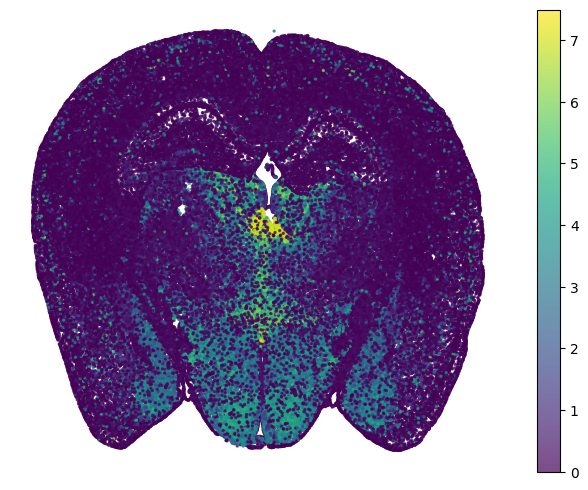

In [32]:
plt.style.use('default')

dmd_expression = merged_dmd['Calb2']
x_coords = merged_dmd['x']
y_coords = merged_dmd['y']

plt.figure(figsize=(8, 6))
scatter = plt.scatter(-x_coords, -y_coords, c=dmd_expression, cmap='viridis', alpha=0.7, s=2)

plt.colorbar()

plt.axis('off')

plt.savefig("dmd_inhipp.png", bbox_inches = 'tight')
plt.show()

In [8]:
Gene_set = ['Oprk1', 'Npbwr1', 'St18', 'Cpa6', 'Tfap2d', 'Tfap2b', 'Pou3f3']
Correlations = pd.Series(index = Gene_set)
plt.style.use('dark_background')

for i in Gene_set:
    Imp_Genes = SpaGE(spatial.T.drop(i,axis=1),merged_df.T,n_pv=10,
                           genes_to_predict = [i])
    Correlations[i] = st.spearmanr(spatial.T[i],Imp_Genes[i])[0]

KeyboardInterrupt: 

In [87]:
Correlations.mean()

0.25066332243208367

In [100]:
sc.pp.highly_variable_genes(merged, n_top_genes=3000)

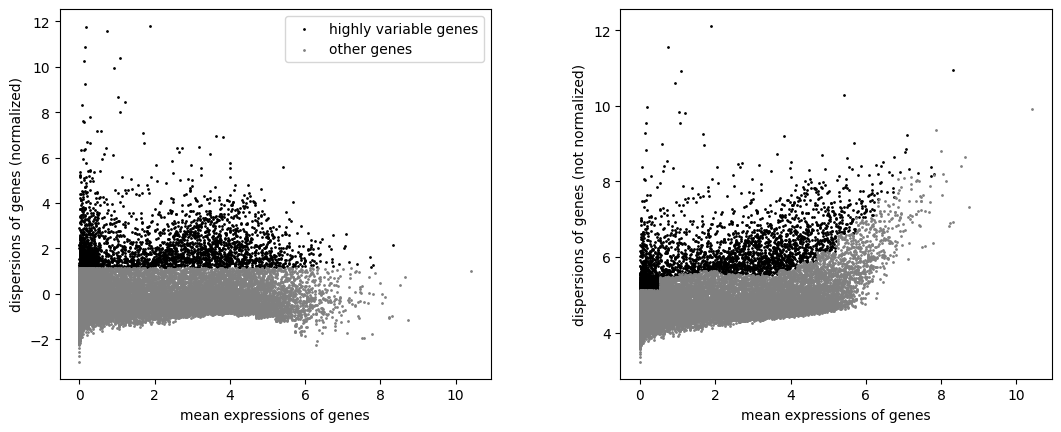

In [102]:
plt.style.use('default')
sc.pl.highly_variable_genes(merged)

In [105]:
merged = merged[:, merged.var.highly_variable]

In [106]:
merged

View of AnnData object with n_obs × n_vars = 170122 × 3000
    obs: 'cell_barcode', 'library_label', 'anatomical_division_label', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'cluster', 'cluster_ann'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'

In [9]:
merged

AnnData object with n_obs × n_vars = 170122 × 26751
    obs: 'cell_barcode', 'library_label', 'anatomical_division_label', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'cluster', 'cluster_ann'

In [10]:
merged.X

<170122x26751 sparse matrix of type '<class 'numpy.float32'>'
	with 853747562 stored elements in Compressed Sparse Row format>

In [ ]:
dmd_expression = merged_df['Dmd']
correaltions =st.spearmanr(merged_df.drop(columns='Dmd'), dmd_expression)